Random matrix theory

Raeding material: before addressing this exercise, it is recommended that i study the chapter on Shrinkage. "26.a.62

Code reference: become familiar with script "s_marchenko_pastur",
which illustrates the spectrum estimation via random matrix theory.

Consider a multivariate i.i.d process of dimension i_bar = 300

In [14]:
from matplotlib.pyplot import legend
from numpy import cov, linspace, pi, sqrt
from numpy import allclose
from numpy.linalg import eigvals
from numpy.random import randn
from scipy.stats import expon, norm as normal
from skrmt.ensemble.spectral_law import MarchenkoPasturDistribution as MP
from seaborn import lineplot, histplot

Task 1:

Suppose the process is normally distributed as follows

Et = (Ei...E100) ~ N(0300x1, ||300).

Generate a set of t_bar = 1,500 observations {Et}t_bar, t=1 , and verify the approximation of sample spectrum
via the Marchenko-Pastur distribution with q=i_bar/t_bar

Run a controlled experiment in 4 steps:
- "Simulate" 1500 days of returns for 300 stocks, that are all independent with variance 1.
The true covariance is identity matrix ||300
- "Estimate" the sample covariance from the data, a 300x300 matrix.
- "Compute its eigenvalues", which gives 300 numbers.
- "Plot" a histogram of those eigenvalues and lay the Marchenko-Pastur (MP) curve on top.
(Check that they match)

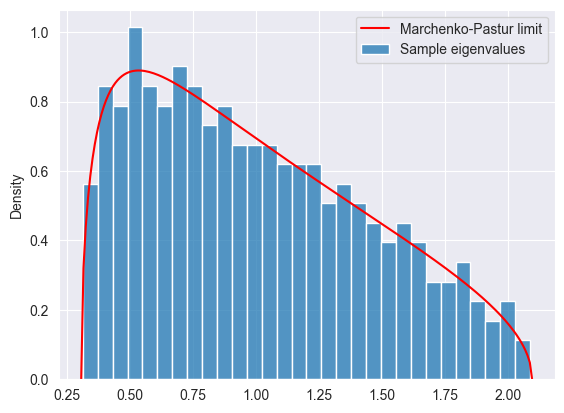

In [15]:
############### inputs ###############
# dimension of process
i_bar = 300
# number of observation
t_bar = 1500
######################################

# the simulated normal scenarios
# randn() draws stand normals, with mean 0 and variance 1, into a 1500x300 array.
# a table of 1500 daily returns for 300 stocks,
eps_1 = randn(t_bar, i_bar)
# the sample covariance matrix for those normal scenarios
sigma2_1 = cov(eps_1.T)
# eigenvalues (lambda) of normal scenarios, returns the 300 eigenvalues.
lam_1 = eigvals(sigma2_1)

# Marchenko-Pasture curve
# the ratio of variables to observations (300/1500=0.2)
q = i_bar / t_bar
# lower bound edges of noise
lam_minus = (1 - sqrt(q))**2
# upper bound edges of noise
lam_plus = (1 + sqrt(q))**2

# define Marchenko-Pastur distribution
# here because ~= 0.2 then first part of this lambda (q > 1) does not switch
# the second part is the MP curve
f_mp = lambda l: ((1 - 1/q) * normal.pdf(l, 0, 10**(-2)) * (q > 1)
                  + 1/(2*pi*l*q)*sqrt((l - lam_minus)*(lam_plus - l)*(lam_minus < l < lam_plus)))

# grid of 200 evenly spaced eigenvalue positions, lambda to lambda (x-xis values)
x_mp = linspace(lam_minus, lam_plus, 200)
# Marchenko-Pastur approximation for the normal and the exponential
# looping through the eigenvalue positions and calculating the heights of each (y-axis values)
y_mp = [f_mp(x) for x in x_mp]

############################### plot ###############################
# normal vs its Marchenko-Pastur approximation
lineplot(x=x_mp, y=y_mp, color='r', label='Marchenko-Pastur limit')
histplot(x=lam_1, stat='density', bins=30, label='Sample eigenvalues')
legend();

In [16]:
# CROSS-CHECK MP formula vs the scikit-rmt library version

# beta=1 means real valued data
mp = MP(ratio=q, beta=1)
# library's curve (which skips the 2 exact edge points)
y_lib = mp.pdf(x_mp[1:-1])
# True means the curves match
print(allclose(y_lib, y_mp[1:-1]))

True


Task 2:

(Non-normal data)  - testing does the Marchenko-Pastur law depend on normal data/

Suppose the process is made by random variables Ei,t that are cross-sectionally independent and identically distributed
as a shifted exponential

Ei,t ~ Exponential(1) - 1.

for any i=1,...,300.

Generate a set of t_bar=1,500 observations {Et}t_bar,t=1' and verify that the approximation in Task 1 still holds.

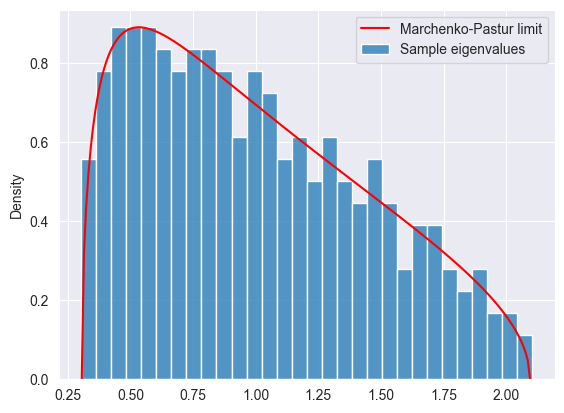

In [17]:
# exponential scenarios, but draws from the exponential dist (1500x300 table)
# - 1 shifts every number down by 1, so the mean becomes 0
eps_2 = expon.rvs(size=(t_bar, i_bar)) - 1
# covariance of exponential scenarios
sigma2_2 = cov(eps_2.T)
# eigenvalues of exponential scenarios
lam_2 = eigvals(sigma2_2)

# covraiance and eigenvalue lines are same as Task 1, only data changes.
# grid
x_mp_2 = x_mp
# Marchenko-Pastur approximation for the normal and the exponential
y_mp_2 = y_mp

################################# plot #################################
# exponential vs its Marchenko-Pastur approximation
lineplot(x=x_mp_2, y=y_mp_2, color='r', label='Marchenko-Pastur limit')
histplot(x=lam_2, stat='density', bins=30, label='Sample eigenvalues')
legend();


Task 3:

(variance 4 instead of 1)

Suppose the process is normally distributed as follows

Et ~N(0 300x1, 4 x || 300).

Generate a set of t_bar=1,500 observations {Et}t_bar,t=1' and verify that the
approximation in Task 1 does not hold more.

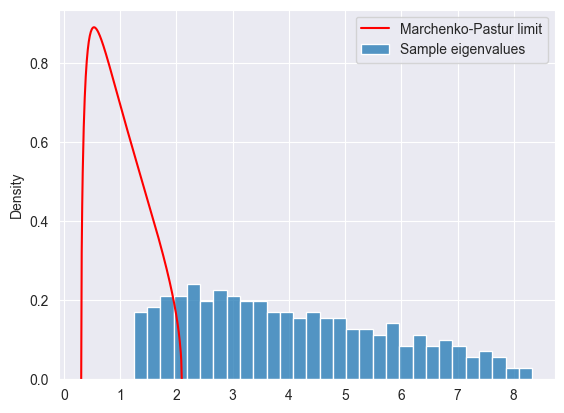

In [18]:
# rescaled normal scenarios with standard deviation 2, so variance of 4
# 2 * randn() turns standard normals into normals with std = 2
eps_3 = 2 * randn(t_bar, i_bar)
# covariance of rescaled normal scenarios
sigma2_3 = cov(eps_3.T, bias=True)
# eigenvalues of rescaled normal scenarios
lam_3 = eigvals(sigma2_3)

# grid: the same unit-variance MP curve as Task 1, unchanged on purpose
x_mp_3 = x_mp
# Marchenko-Pastur approximation (still assumes variance 1)
y_mp_3 = y_mp

################################# plot #################################
# rescaled normal vs unit variance Marchenko-Pastur approximation
lineplot(x=x_mp_3, y=y_mp_3, color='r', label='Marchenko-Pastur limit')
histplot(x=lam_3, stat='density', bins=30, label='Sample eigenvalues')
legend();

# The red curve and the histogram are obviously in disagreement - hence the mismatch
# with eigenvalue x 4, this spreads the probability out over 4 times the range, and the bars are about
# only 1/4 the height also

Task 4:

Comment the results obtained in Task 1, Task 2, Task 3, (max 80 words)

Hint; Check the processes which verify the constraints.

Answer:

Answer:

MP describes the sample eigenvalues of standardised noise with entries i.i.d across variables (0 mean and unit variance)
Task1(normal): satisfies this - curve matches the histogram
Task2(shifted exponential): is skewed right but still i.i.d with 0 mean and variance 1, so the fit holds, shape of distribution doesnt matter.
Task3(variance4): breaks the unit variance constraint, eigenvalues stretch by a factor of 4 and are outside the band.  Rescaling would restore the fit

### Additional check: Marchenko-Pastur rescaled for variance 4

Unit-variance band [0.31, 2.09]: 16.3% of eigenvalues inside
Rescaled band (x4) [1.22, 8.38]: 100.0% of eigenvalues inside


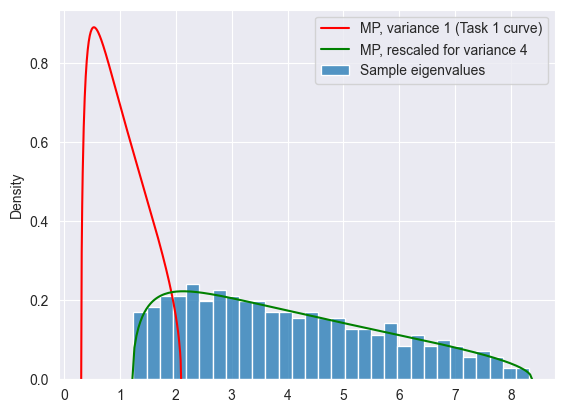

In [19]:
############### inputs ###############
# true variance of each variable in Task 3
sigma2_true = 4
######################################

# rescaled band edges: every eigenvalue is stretched by sigma2_true
lam_minus_4 = sigma2_true * lam_minus
lam_plus_4 = sigma2_true * lam_plus

# rescaled grid: the Task 1 grid stretched by sigma2_true
x_mp_4 = sigma2_true * x_mp
# rescaled MP curve: squeeze x back to unit variance, then divide height
y_mp_4 = [f_mp(x / sigma2_true) / sigma2_true for x in x_mp_4]

# share of sample eigenvalues inside each band
# drop any tiny imaginary parts of eigenvalues
lam_3_real = lam_3.real
inside_unit = ((lam_3_real > lam_minus) & (lam_3_real < lam_plus)).mean()
inside_scaled = ((lam_3_real > lam_minus_4) & (lam_3_real < lam_plus_4)).mean()

print(f'Unit-variance band [{lam_minus:.2f}, {lam_plus:.2f}]: {inside_unit:.1%} of eigenvalues inside')
print(f'Rescaled band (x{sigma2_true}) [{lam_minus_4:.2f}, {lam_plus_4:.2f}]: {inside_scaled:.1%} of eigenvalues inside')


################################# plot #################################
lineplot(x=x_mp, y=y_mp, color='r', label='MP, variance 1 (Task 1 curve)')
lineplot(x=x_mp_4, y=y_mp_4, color='g', label='MP, rescaled for variance 4')
histplot(x=lam_3, stat='density', bins=30, label='Sample eigenvalues')
legend();

Conclusion:

In real life I should use Marchenko Pastur whenever i've estimated a large correlation or covariance
matrix from limited data and i need to know which parts of it is real and which part is noise.

Thecore idea in 1 example:

Suppose i estimate the correlation matrix of 500 of the S&P stocks for 2 years of daily data, about 500 days.  Then q = 500/500 = 1, so the noise runs from 0-4

So when i compute the eigenvalues of that matrix, the typical picture looks like this;

One huge eigenvalue far above 4 (This is the market factor)

A handful of eigenvalues just above 4 (These are sector factors)

Most of the rest(90% often more) inside the band. by MP these are indistinuishable from what pure noise would produce.

So a 500x500 matrix with 125,000 distinct correlations, may contain only a dozen or so real directions.
Everything else is estimated noise.



Where it is used:

1. Cleaning covariance matrices before portfolio optimisation.
2. Choosing how many factors to keep in PCA
3. Risk models.
4. Checking whether apparent structure is real.
5. Portfolios of trading strategies.



Interview knowings:

The band edge is fuzzy in practice. With finite samples, a pure-noise eigenvalue can poke slightly above λ₊. Treat values just past the edge with some suspicion.

Real returns violate the assumptions.
They have fat tails, volatility clustering and changing correlations, while Marchenko-Pastur assumes i.i.d. data. Universality (Task 2) covers different shapes, but not dependence over time. That's one reason ARPM works with invariants, such as GARCH-filtered residuals, rather than raw returns.


The market factor distorts the picture.
One huge eigenvalue uses up part of the total variance, so the noise eigenvalues are slightly smaller than 1 on average.
More careful versions fit the noise level σ² instead of assuming it's 1. That's the Task 3 rescaling idea, applied to real data.

Flexible probabilities change your effective sample size.

If you weight recent days more heavily, the relevant sample size is closer to the effective number of scenarios than to t̄, which widens the band. This links directly to your project's Task 2 choices.